In [69]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, BisectingKMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

In [70]:
#load dataset
df = pd.read_csv("Wholesale customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [71]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [72]:
df.shape

(440, 8)

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [74]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [75]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [76]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [77]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [78]:
meta = df[["Channel", "Region"]].reset_index(drop=True)
X = df.drop(columns=["Channel", "Region"]).reset_index(drop=True)
features = list(X.columns)
print("\nDropped (categorical codes):  Channel, Region")
print("Features used:", features)


Dropped (categorical codes):  Channel, Region
Features used: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


In [79]:
X_scaled = StandardScaler().fit_transform(X)
print("\nScaled mean (approx 0):", np.round(X_scaled.mean(axis=0), 3))
print("Scaled std  (approx 1):", np.round(X_scaled.std(axis=0), 3))


Scaled mean (approx 0): [-0.  0. -0.  0.  0. -0.]
Scaled std  (approx 1): [1. 1. 1. 1. 1. 1.]


In [80]:
dist_vec = {m: pdist(X_scaled, metric=m) for m in ["euclidean", "cityblock", "cosine"]}
dist_mat = {m: squareform(v) for m, v in dist_vec.items()}
for m, D in dist_mat.items():
    print(f"\n{m.capitalize()} distance matrix  shape={D.shape}")
    print("  top-left 5x5 block:\n", np.round(D[:5, :5], 3))
    print(f"  mean={dist_vec[m].mean():.3f}  min={dist_vec[m].min():.3f}  max={dist_vec[m].max():.3f}")


Euclidean distance matrix  shape=(440, 440)
  top-left 5x5 block:
 [[0.    0.621 2.415 1.818 1.854]
 [0.621 0.    2.173 1.784 1.923]
 [2.415 2.173 0.    2.683 1.73 ]
 [1.818 1.784 2.683 0.    1.662]
 [1.854 1.923 1.73  1.662 0.   ]]
  mean=2.585  min=0.044  max=21.268

Cityblock distance matrix  shape=(440, 440)
  top-left 5x5 block:
 [[0.    1.281 3.566 3.438 3.719]
 [1.281 0.    2.724 3.77  4.051]
 [3.566 2.724 0.    5.551 3.42 ]
 [3.438 3.77  5.551 0.    3.611]
 [3.719 4.051 3.42  3.611 0.   ]]
  mean=4.855  min=0.092  max=44.536

Cosine distance matrix  shape=(440, 440)
  top-left 5x5 block:
 [[0.    0.32  0.936 1.771 1.126]
 [0.32  0.    0.635 1.781 1.271]
 [0.936 0.635 0.    1.091 0.33 ]
 [1.771 1.781 1.091 0.    0.718]
 [1.126 1.271 0.33  0.718 0.   ]]
  mean=0.935  min=0.000  max=1.995


In [81]:
K = 3
linkages = ["single", "complete", "average", "ward"]
rows = []
labels_store = {}
Z_store = {}
for metric in ["euclidean", "cityblock", "cosine"]:
    for link in linkages:
        if link == "ward" and metric != "euclidean":
            continue  # Ward is only defined for Euclidean distance
        Z = linkage(X_scaled, method=link, metric=metric)
        lab = fcluster(Z, K, criterion="maxclust") - 1
        Z_store[(metric, link)] = Z
        labels_store[(metric, link)] = lab
        coph, _ = cophenet(Z, dist_vec[metric])
        sizes = np.bincount(lab, minlength=K)
        rows.append(dict(Metric=metric, Linkage=link,
                         Silhouette=silhouette_score(X_scaled, lab, metric=metric if metric != "cityblock" else "manhattan"),
                         DaviesBouldin=davies_bouldin_score(X_scaled, lab),
                         CalinskiHarabasz=calinski_harabasz_score(X_scaled, lab),
                         Cophenetic=coph, ClusterSizes=sizes.tolist()))
res = pd.DataFrame(rows).round(3)
pd.set_option("display.width", 200)
display(res)

,Metric,Linkage,Silhouette,DaviesBouldin,CalinskiHarabasz,Cophenetic,ClusterSizes
0,euclidean,single,0.797,0.123,51.431,0.902,"[438, 1, 1]"
1,euclidean,complete,0.712,0.513,116.952,0.838,"[10, 429, 1]"
2,euclidean,average,0.768,0.452,97.883,0.934,"[5, 434, 1]"
3,euclidean,ward,0.265,1.285,111.151,0.415,"[6, 153, 281]"
4,cityblock,single,0.744,0.123,51.431,0.888,"[438, 1, 1]"
5,cityblock,complete,0.625,0.604,125.330,0.759,"[22, 417, 1]"
6,cityblock,average,0.762,0.452,97.883,0.926,"[5, 434, 1]"
7,cosine,single,-0.082,2.215,0.114,0.325,"[438, 1, 1]"
8,cosine,complete,0.424,1.427,92.780,0.623,"[176, 106, 158]"
9,cosine,average,0.498,1.437,95.934,0.755,"[125, 200, 115]"


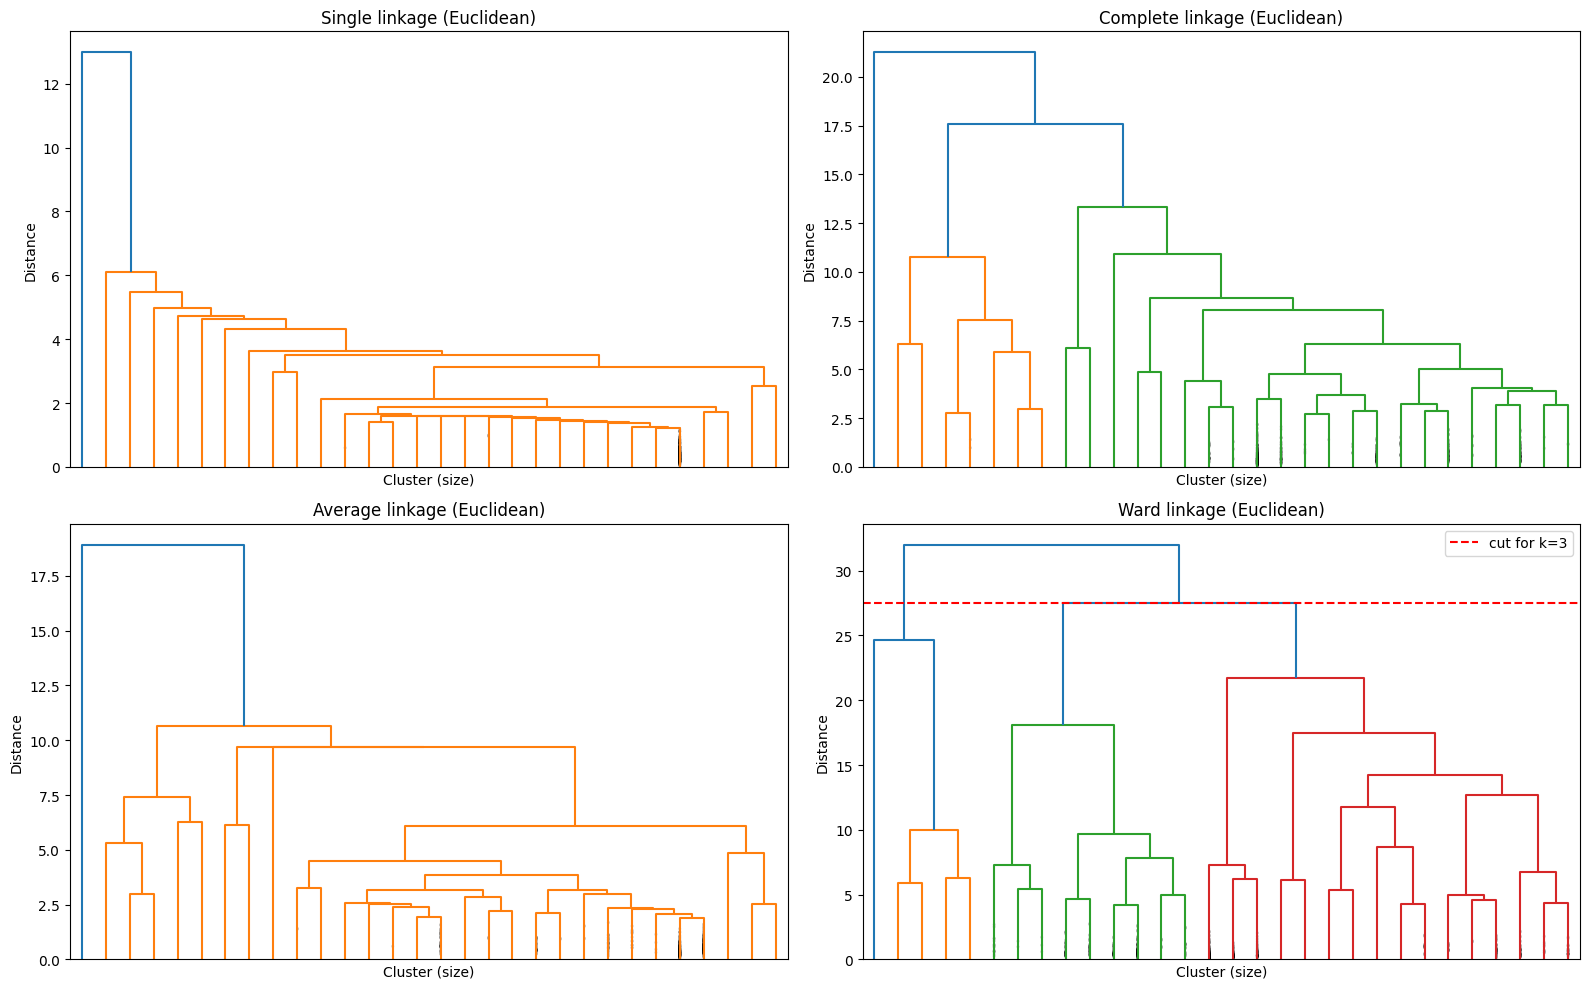

In [82]:
plt.ion()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, link in zip(axes.ravel(), linkages):
    Z = Z_store[("euclidean", link)]
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, no_labels=True,
               show_contracted=True)
    if link == "ward":
        ax.axhline(y=Z[-K + 1, 2] - 1e-6, color="r", ls="--", label=f"cut for k={K}")
        ax.legend()
    ax.set_title(f"{link.capitalize()} linkage (Euclidean)")
    ax.set_xlabel("Cluster (size)"); ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

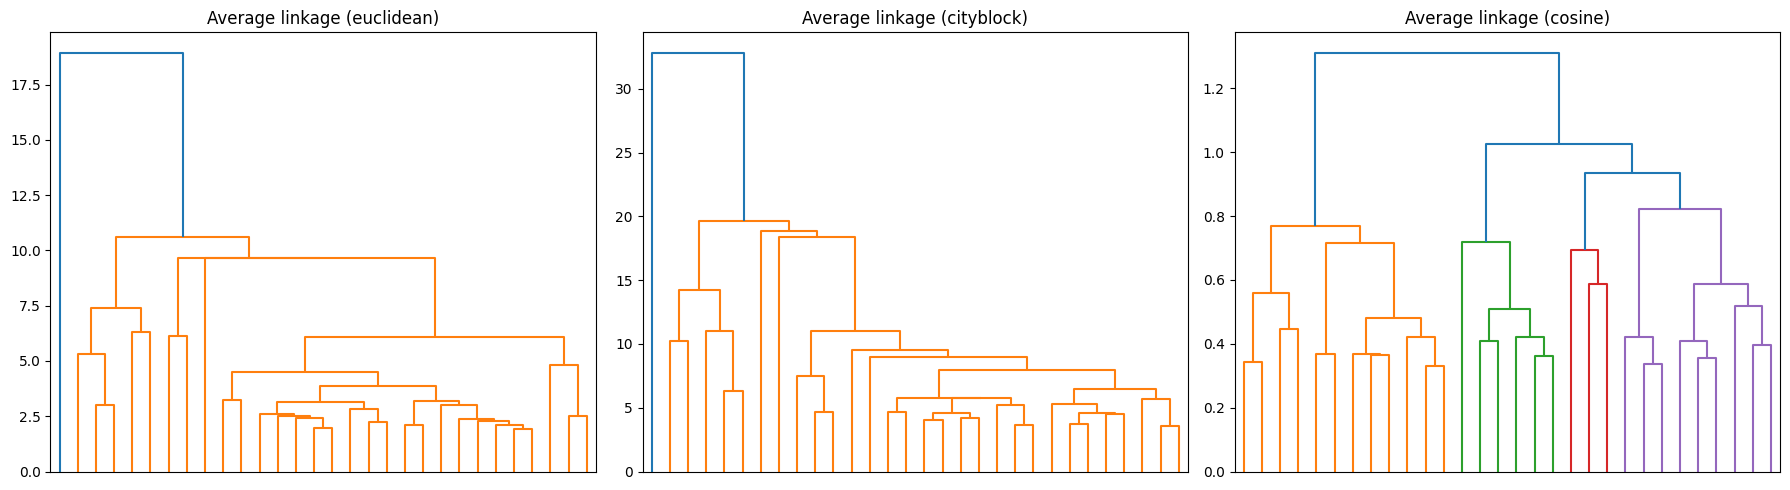

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["euclidean", "cityblock", "cosine"]):
    dendrogram(Z_store[(metric, "average")], truncate_mode="lastp", p=30, ax=ax, no_labels=True)
    ax.set_title(f"Average linkage ({metric})")
plt.tight_layout()
plt.show()

In [84]:
Zw = Z_store[("euclidean", "ward")]
print("Last 8 Ward merge heights:", np.round(Zw[-8:, 2], 2))
print("Gaps between successive heights (largest gap suggests the cut):",
      np.round(np.diff(Zw[-8:, 2]), 2))
print("Saved: dendrograms_linkages.png, dendrograms_metrics.png")

Last 8 Ward merge heights: [12.65 14.21 17.48 18.06 21.72 24.68 27.49 32.01]
Gaps between successive heights (largest gap suggests the cut): [1.56 3.27 0.58 3.66 2.96 2.81 4.51]
Saved: dendrograms_linkages.png, dendrograms_metrics.png


In [85]:
div = BisectingKMeans(n_clusters=K, bisecting_strategy="biggest_inertia",
                      random_state=42, n_init=10)
div_lab = div.fit_predict(X_scaled)
ward_lab = labels_store[("euclidean", "ward")]
print("Divisive cluster sizes     :", np.bincount(div_lab).tolist())
print("Agglo (Ward) cluster sizes :", np.bincount(ward_lab).tolist())
print(f"Divisive  silhouette={silhouette_score(X_scaled, div_lab):.3f}  "
      f"DB={davies_bouldin_score(X_scaled, div_lab):.3f}  "
      f"CH={calinski_harabasz_score(X_scaled, div_lab):.1f}")
print(f"Agglo-Ward silhouette={silhouette_score(X_scaled, ward_lab):.3f}  "
      f"DB={davies_bouldin_score(X_scaled, ward_lab):.3f}  "
      f"CH={calinski_harabasz_score(X_scaled, ward_lab):.1f}")
print("Adjusted Rand Index (Divisive vs Ward):",
      round(adjusted_rand_score(div_lab, ward_lab), 3))
print("Adjusted Rand Index (Divisive vs Average):",
      round(adjusted_rand_score(div_lab, labels_store[("euclidean", "average")]), 3))

Divisive cluster sizes     : [4, 49, 387]
Agglo (Ward) cluster sizes : [6, 153, 281]
Divisive  silhouette=0.525  DB=1.037  CH=138.5
Agglo-Ward silhouette=0.265  DB=1.285  CH=111.2
Adjusted Rand Index (Divisive vs Ward): 0.218
Adjusted Rand Index (Divisive vs Average): 0.165


In [86]:
ks = range(2, 9)
exp = []
for k in ks:
    for name, model in [("Ward", AgglomerativeClustering(n_clusters=k, linkage="ward")),
                        ("Average", AgglomerativeClustering(n_clusters=k, linkage="average")),
                        ("Divisive", BisectingKMeans(n_clusters=k, random_state=42, n_init=10))]:
        lab = model.fit_predict(X_scaled)
        exp.append(dict(k=k, Method=name,
                        Silhouette=silhouette_score(X_scaled, lab),
                        CH=calinski_harabasz_score(X_scaled, lab),
                        Sizes=sorted(np.bincount(lab).tolist(), reverse=True)))
exp = pd.DataFrame(exp)
display(exp.round(3))

,k,Method,Silhouette,CH,Sizes
0,2,Ward,0.792,105.442,"[434, 6]"
1,2,Average,0.864,67.512,"[439, 1]"
2,2,Divisive,0.553,153.528,"[387, 53]"
3,3,Ward,0.265,111.151,"[281, 153, 6]"
4,3,Average,0.768,97.883,"[434, 5, 1]"
5,3,Divisive,0.525,138.549,"[387, 49, 4]"
6,4,Ward,0.267,120.131,"[281, 153, 5, 1]"
7,4,Average,0.745,87.722,"[432, 5, 2, 1]"
8,4,Divisive,0.356,136.277,"[307, 80, 49, 4]"
9,5,Ward,0.240,128.645,"[177, 153, 104, 5, 1]"


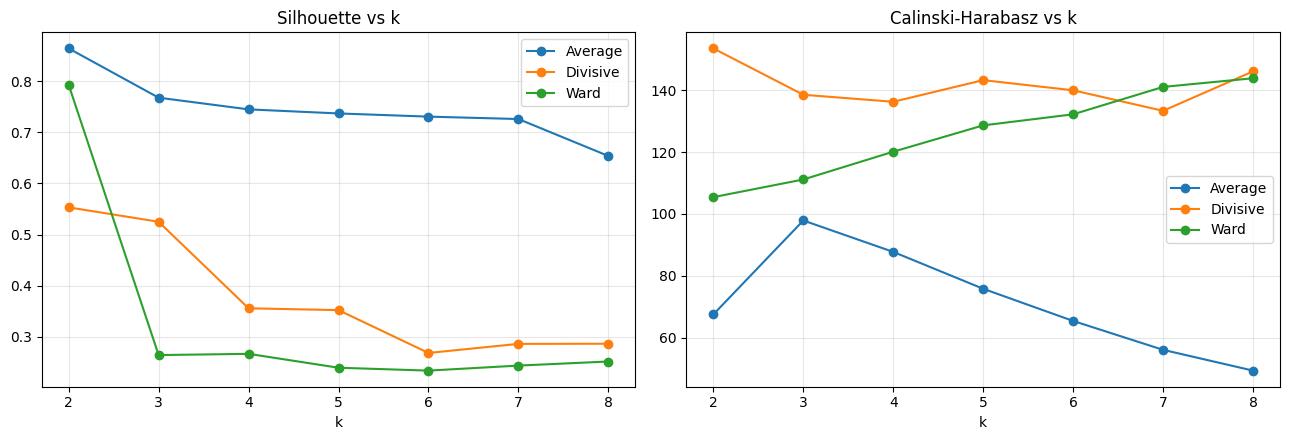

In [87]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.ion()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, g in exp.groupby("Method"):
    ax[0].plot(g.k, g.Silhouette, marker="o", label=name)
    ax[1].plot(g.k, g.CH, marker="o", label=name)
ax[0].set_title("Silhouette vs k"); ax[1].set_title("Calinski-Harabasz vs k")
for a in ax: a.set_xlabel("k"); a.legend(); a.grid(alpha=.3)
plt.tight_layout()
plt.show()

In [88]:
print("\nWard cluster sizes as k increases (shows nested splitting):")
for k in range(2, 7):
    l = fcluster(Zw, k, criterion="maxclust")
    print(f"  k={k}: {sorted(np.bincount(l)[1:].tolist(), reverse=True)}")


Ward cluster sizes as k increases (shows nested splitting):
  k=2: [434, 6]
  k=3: [281, 153, 6]
  k=4: [281, 153, 5, 1]
  k=5: [177, 153, 104, 5, 1]
  k=6: [177, 127, 104, 26, 5, 1]


Explained variance ratio: [0.441 0.284] total = 0.725
PC loadings:
                     PC1    PC2
Fresh             0.043  0.528
Milk              0.545  0.083
Grocery           0.579 -0.146
Frozen            0.051  0.611
Detergents_Paper  0.549 -0.255
Delicassen        0.249  0.504


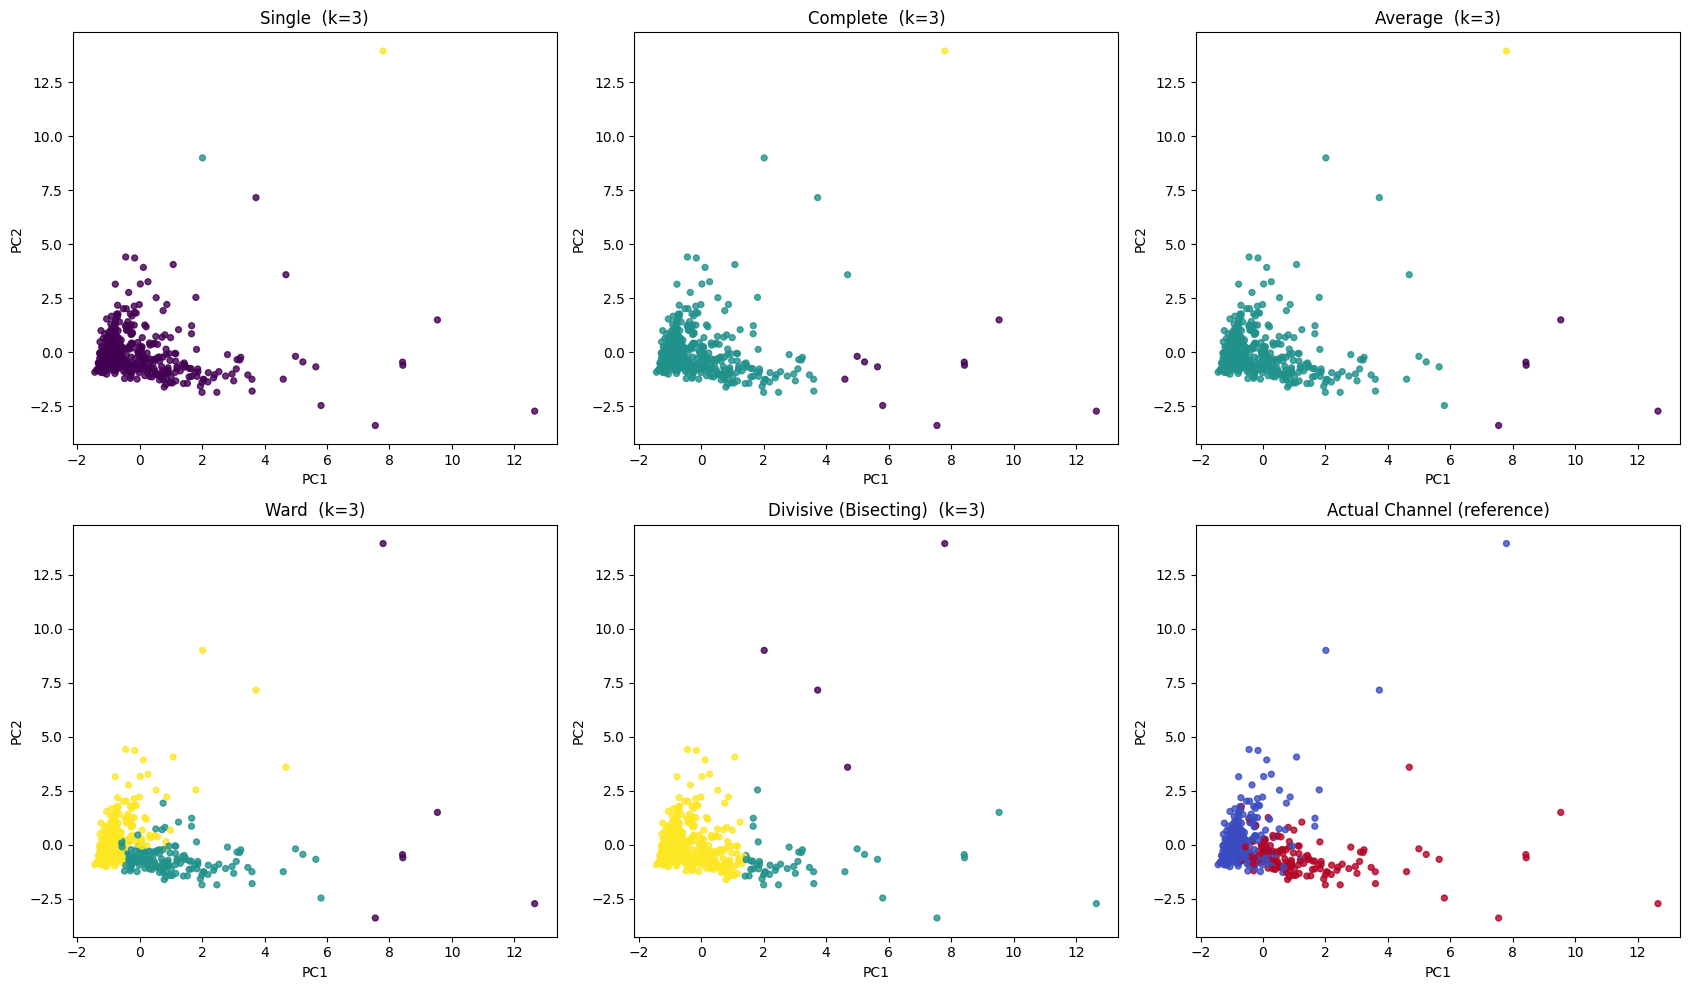

In [89]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.ion()

pca = PCA(n_components=2)
P = pca.fit_transform(X_scaled)
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 3),
      "total =", round(pca.explained_variance_ratio_.sum(), 3))
print("PC loadings:\n", pd.DataFrame(pca.components_.T, index=features,
                                      columns=["PC1", "PC2"]).round(3))

panels = [("Single", labels_store[("euclidean", "single")]),
          ("Complete", labels_store[("euclidean", "complete")]),
          ("Average", labels_store[("euclidean", "average")]),
          ("Ward", ward_lab),
          ("Divisive (Bisecting)", div_lab)]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (name, lab) in zip(axes.ravel(), panels):
    sc = ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="viridis", s=18, alpha=.8)
    ax.set_title(f"{name}  (k={K})"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax = axes.ravel()[-1]
ax.scatter(P[:, 0], P[:, 1], c=meta["Channel"], cmap="coolwarm", s=18, alpha=.8)
ax.set_title("Actual Channel (reference)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

In [90]:
keys = list(labels_store.keys()) + [("bisecting", "divisive")]
labs = {**labels_store, ("bisecting", "divisive"): div_lab}
names = [f"{m[:4]}-{l}" for m, l in keys]
ari = pd.DataFrame([[adjusted_rand_score(labs[a], labs[b]) for b in keys] for a in keys],
                   index=names, columns=names).round(2)
print("Adjusted Rand Index between configurations:")
display(ari)

Adjusted Rand Index between configurations:


,eucl-single,eucl-complete,eucl-average,eucl-ward,city-single,city-complete,city-average,cosi-single,cosi-complete,cosi-average,bise-divisive
eucl-single,1.00,0.15,0.24,0.01,1.00,0.07,0.24,-0.00,-0.00,0.00,0.06
eucl-complete,0.15,1.00,0.69,0.08,0.15,0.62,0.69,-0.01,0.02,0.01,0.28
eucl-average,0.24,0.69,1.00,0.06,0.24,0.39,1.00,-0.01,0.01,0.01,0.16
eucl-ward,0.01,0.08,0.06,1.00,0.01,0.12,0.06,0.01,0.32,0.43,0.22
city-single,1.00,0.15,0.24,0.01,1.00,0.07,0.24,-0.00,-0.00,0.00,0.06
city-complete,0.07,0.62,0.39,0.12,0.07,1.00,0.39,-0.01,0.04,0.03,0.53
city-average,0.24,0.69,1.00,0.06,0.24,0.39,1.00,-0.01,0.01,0.01,0.16
cosi-single,-0.00,-0.01,-0.01,0.01,-0.00,-0.01,-0.01,1.00,0.00,0.00,-0.01
cosi-complete,-0.00,0.02,0.01,0.32,-0.00,0.04,0.01,0.00,1.00,0.50,0.12
cosi-average,0.00,0.01,0.01,0.43,0.00,0.03,0.01,0.00,0.50,1.00,0.10


In [91]:
for name, lab in [("Ward k=3", ward_lab), ("Divisive k=3", div_lab)]:
    prof = X.copy(); prof["Cluster"] = lab
    print(f"\n--- {name}: mean spend per cluster ---")
    out = prof.groupby("Cluster").mean().round(0)
    out["Size"] = prof.groupby("Cluster").size()
    out["%Horeca(Ch1)"] = (meta.groupby(lab)["Channel"].apply(lambda s: (s == 1).mean() * 100)).round(1)
    print(out.to_string())


TASK 10: CLUSTER INTERPRETATION

--- Ward k=3: mean spend per cluster ---
           Fresh     Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Size  %Horeca(Ch1)
Cluster                                                                                     
0        27477.0  43542.0  54588.0  8286.0           25018.0     10248.0     6          16.7
1         5794.0   9420.0  13762.0  1462.0            5913.0      1578.0   153          26.1
2        15049.0   3017.0   3792.0  3837.0             758.0      1310.0   281          91.5

--- Divisive k=3: mean spend per cluster ---
           Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen  Size  %Horeca(Ch1)
Cluster                                                                                      
0        52022.0  31696.0  18491.0  29826.0            2699.0     19656.0     4          75.0
1         7856.0  18061.0  27599.0   2110.0           12598.0      2251.0    49           6.1
2        12111.0   3976.0   5355.0   2

In [92]:
for k in (2, 4):
    lab = fcluster(Zw, k, criterion="maxclust") - 1
    prof = X.copy(); prof["Cluster"] = lab
    out = prof.groupby("Cluster").mean().round(0); out["Size"] = prof.groupby("Cluster").size()
    print(f"\n--- Ward k={k} profile ---"); print(out.to_string())


--- Ward k=2 profile ---
           Fresh     Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Size
Cluster                                                                       
0        27477.0  43542.0  54588.0  8286.0           25018.0     10248.0     6
1        11786.0   5274.0   7307.0  3000.0            2575.0      1404.0   434

--- Ward k=4 profile ---
           Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen  Size
Cluster                                                                        
0        25603.0  43461.0  61472.0   2636.0           29974.0      2709.0     5
1        36847.0  43950.0  20170.0  36534.0             239.0     47943.0     1
2         5794.0   9420.0  13762.0   1462.0            5913.0      1578.0   153
3        15049.0   3017.0   3792.0   3837.0             758.0      1310.0   281
